# SFS / SHS survey moments

Load Canadian Survey of Financial Security (1999–2023) and Survey of Household Spending (Tier A 2017/19/23 + Tier B 1997–2009), then compute **weighted** aggregates.

Requires `data/local_paths.yaml` (see `local_paths.example.yaml`). Microdata stays outside git.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src.survey import (
    load_local_paths,
    load_sfs,
    load_shs_all,
    sfs_aggregate_moments,
    sfs_distribution_moments,
    shs_cy_moments,
)

paths = load_local_paths()
for k, v in paths.items():
    print(f"{k}: {v}  exists={v.exists()}")

out = ROOT / "output" / "survey"
out.mkdir(parents=True, exist_ok=True)
print("figures ->", out)


sfs_panel: C:\Users\thoma\Dropbox\CA_costsinflation\data\raw\sfs\sfs1999_2023.csv  exists=True
shs_ry2023: C:\Users\thoma\Dropbox\SHS\RY2023  exists=True
shs_edm: C:\Users\thoma\Dropbox\dataSHS\3508_SHS_EDM  exists=True
shs_consolidated: C:\Users\thoma\Dropbox\HRAM2\survey_data\clean\SHS\SHS_consolidated_data.csv  exists=True
figures -> c:\Users\thoma\Dropbox\HAmodel\portfolio_olg\output\survey


## SFS: ownership, housing/financial shares of NW, NW/Y

Primary net worth excludes autos:

$$NW = H^{gross}-D^H + F^{gross}-D^F = H^{net}+F^{net}.$$

Shares are aggregate ratios $\sum w X / \sum w\, NW$ (gross and net).

In [2]:
sfs = load_sfs()
print("years", sorted(sfs["year"].dropna().unique().tolist()), "n=", len(sfs))
# Identity check
err = (sfs["nw"] - (sfs["housing_net"] + sfs["financial_net"])).abs().max()
print("max |nw - (H_net+F_net)|", float(err))

sfs_m = sfs_aggregate_moments(sfs, by="year")
display(sfs_m)
sfs_m.to_csv(out / "sfs_aggregate_moments.csv", index=False)
print("Wrote", out / "sfs_aggregate_moments.csv")


years [1999, 2005, 2012, 2016, 2019, 2023] n= 72295
max |nw - (H_net+F_net)| 0.0


,year,n,homeownership,housing_share_gross,housing_share_net,financial_share_gross,financial_share_net,nw_to_netincome,mean_nw,mean_inc_net
0,1999,15933,0.603610,0.460498,0.339387,0.685587,0.660613,5.875234,235676.016276,39606.664641
1,2005,5267,0.619233,0.498133,0.377418,0.652526,0.622582,7.162824,354766.099796,49233.910960
2,2012,12003,0.625384,0.529420,0.399184,0.630090,0.600816,8.615845,542062.681502,62867.826142
3,2016,12429,0.618483,0.549316,0.409070,0.614730,0.590930,9.435752,657032.000183,69474.990700
4,2019,10422,0.624058,0.542800,0.411937,0.609364,0.588063,9.777843,729504.720935,74667.037859
5,2023,16241,0.647863,0.555464,0.432459,0.586084,0.567541,11.191541,976682.613289,87111.143632


Wrote c:\Users\thoma\Dropbox\HAmodel\portfolio_olg\output\survey\sfs_aggregate_moments.csv


### SFS figures

Weighted survey-year aggregates: homeownership, housing vs financial shares of primary NW, and aggregate NW / net income.

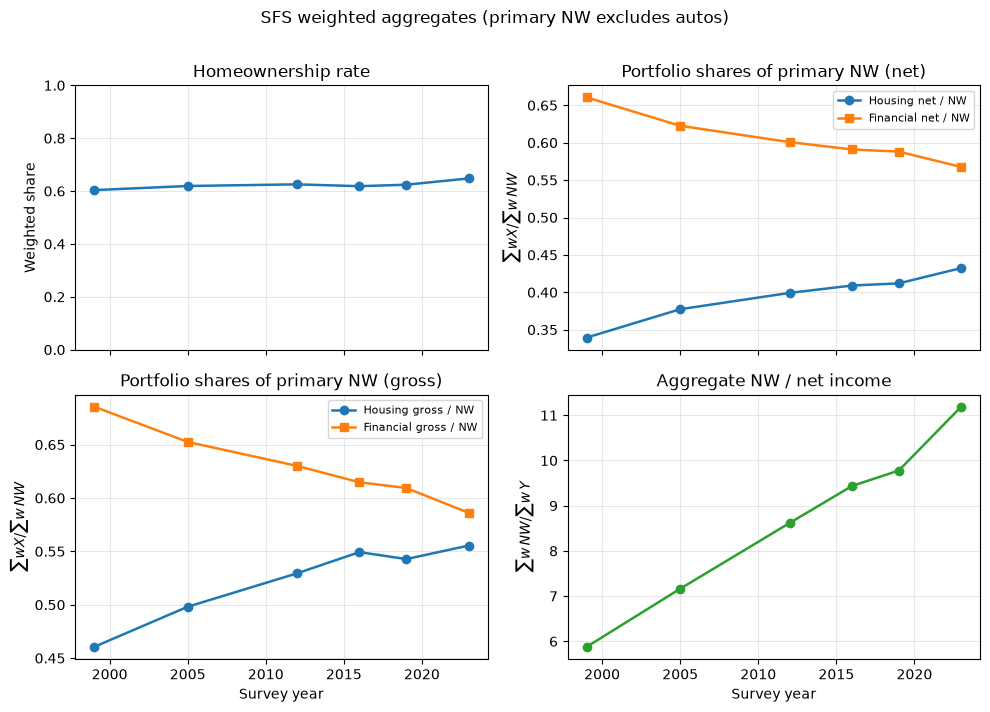

Wrote c:\Users\thoma\Dropbox\HAmodel\portfolio_olg\output\survey\sfs_aggregate_moments.png


In [3]:
fig, axes = plt.subplots(2, 2, figsize=(10, 7), sharex=True)
m = sfs_m.sort_values("year")

axes[0, 0].plot(m["year"], m["homeownership"], marker="o", lw=1.8)
axes[0, 0].set_title("Homeownership rate")
axes[0, 0].set_ylabel("Weighted share")
axes[0, 0].set_ylim(0, 1)
axes[0, 0].grid(True, alpha=0.3)

axes[0, 1].plot(m["year"], m["housing_share_net"], marker="o", lw=1.8, label="Housing net / NW")
axes[0, 1].plot(m["year"], m["financial_share_net"], marker="s", lw=1.8, label="Financial net / NW")
axes[0, 1].set_title("Portfolio shares of primary NW (net)")
axes[0, 1].set_ylabel(r"$\sum w X / \sum w\, NW$")
axes[0, 1].legend(fontsize=8)
axes[0, 1].grid(True, alpha=0.3)

axes[1, 0].plot(m["year"], m["housing_share_gross"], marker="o", lw=1.8, label="Housing gross / NW")
axes[1, 0].plot(m["year"], m["financial_share_gross"], marker="s", lw=1.8, label="Financial gross / NW")
axes[1, 0].set_title("Portfolio shares of primary NW (gross)")
axes[1, 0].set_xlabel("Survey year")
axes[1, 0].set_ylabel(r"$\sum w X / \sum w\, NW$")
axes[1, 0].legend(fontsize=8)
axes[1, 0].grid(True, alpha=0.3)

axes[1, 1].plot(m["year"], m["nw_to_netincome"], marker="o", lw=1.8, color="C2")
axes[1, 1].set_title("Aggregate NW / net income")
axes[1, 1].set_xlabel("Survey year")
axes[1, 1].set_ylabel(r"$\sum w\, NW / \sum w\, Y$")
axes[1, 1].grid(True, alpha=0.3)

fig.suptitle("SFS weighted aggregates (primary NW excludes autos)", y=1.01)
fig.tight_layout()
fig.savefig(out / "sfs_aggregate_moments.png", dpi=140, bbox_inches="tight")
plt.show()
print("Wrote", out / "sfs_aggregate_moments.png")


### SFS distributions: mean and major quantiles

Weighted mean and p10/p25/p50/p75/p90 by survey year for net worth, net income,
net housing wealth, net financial wealth, and household housing portfolio share
`H_net / NW` (rows with `|NW| < 1` dropped for the share).


In [4]:
sfs_dist = sfs_distribution_moments(sfs, by="year")
display(sfs_dist.head(20))

# Wide view: one block per variable
sfs_dist_wide = (
    sfs_dist.pivot_table(
        index=["year", "variable", "label", "n"],
        columns="stat",
        values="value",
        aggfunc="first",
    )
    .reset_index()
)
stat_cols = [c for c in ["mean", "p10", "p25", "p50", "p75", "p90"] if c in sfs_dist_wide.columns]
sfs_dist_wide = sfs_dist_wide[["year", "variable", "label", "n"] + stat_cols].sort_values(
    ["variable", "year"]
)
display(sfs_dist_wide)

sfs_dist.to_csv(out / "sfs_distribution_moments_long.csv", index=False)
sfs_dist_wide.to_csv(out / "sfs_distribution_moments.csv", index=False)
print("Wrote", out / "sfs_distribution_moments.csv")


,year,variable,label,n,stat,value
0,1999,nw,Net worth (ex-auto),15933,mean,235676.016276
1,1999,nw,Net worth (ex-auto),15933,p10,900.000000
2,1999,nw,Net worth (ex-auto),15933,p25,16300.000000
3,1999,nw,Net worth (ex-auto),15933,p50,102800.000000
4,1999,nw,Net worth (ex-auto),15933,p75,285450.000000
5,1999,nw,Net worth (ex-auto),15933,p90,575250.000000
6,1999,inc_net,Net income,15933,mean,39402.279297
7,1999,inc_net,Net income,15933,p10,11000.000000
8,1999,inc_net,Net income,15933,p25,19100.000000
9,1999,inc_net,Net income,15933,p50,33300.000000


stat,year,variable,label,n,mean,p10,p25,p50,p75,p90
0,1999,financial_net,Net financial wealth,15933,155690.694831,325.0,8020.0,48200.000000,1.700000e+05,3.995000e+05
5,2005,financial_net,Net financial wealth,5267,220871.119599,200.0,7675.0,58100.000000,2.335000e+05,5.572500e+05
10,2012,financial_net,Net financial wealth,12003,325679.983840,-1150.0,8475.0,83000.000000,3.710000e+05,9.017500e+05
15,2016,financial_net,Net financial wealth,12429,388259.671059,250.0,11700.0,110750.000000,4.555000e+05,1.016000e+06
20,2019,financial_net,Net financial wealth,10422,428994.921198,550.0,17850.0,127000.000000,4.607500e+05,1.117005e+06
25,2023,financial_net,Net financial wealth,16241,554307.444370,2450.0,37900.0,197600.000000,6.525000e+05,1.471000e+06
1,1999,housing_net,Net housing wealth,15933,79985.321445,0.0,0.0,35000.000000,1.100000e+05,2.075000e+05
6,2005,housing_net,Net housing wealth,5267,133894.980197,0.0,0.0,60000.000000,1.700000e+05,3.280000e+05
11,2012,housing_net,Net housing wealth,12003,216382.697662,0.0,0.0,95000.000000,2.900000e+05,5.500000e+05
16,2016,housing_net,Net housing wealth,12429,268772.329124,0.0,0.0,105000.000000,3.300000e+05,6.900000e+05


Wrote c:\Users\thoma\Dropbox\HAmodel\portfolio_olg\output\survey\sfs_distribution_moments.csv


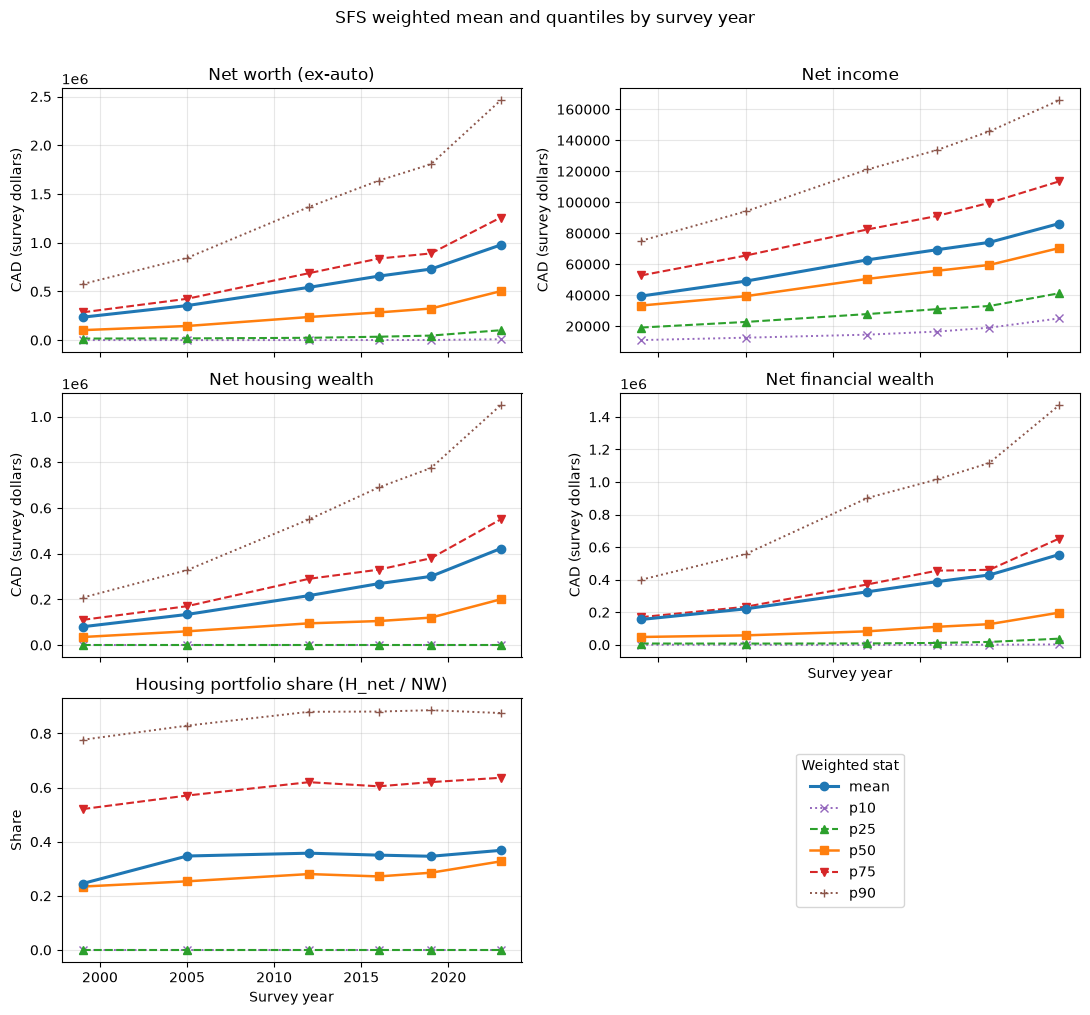

Wrote c:\Users\thoma\Dropbox\HAmodel\portfolio_olg\output\survey\sfs_distribution_moments.png


In [5]:
# One panel per variable; mean + quantiles as distinct styles
STAT_STYLE = {
    "mean": dict(color="C0", ls="-", lw=2.2, marker="o", zorder=5),
    "p50": dict(color="C1", ls="-", lw=1.8, marker="s"),
    "p25": dict(color="C2", ls="--", lw=1.5, marker="^"),
    "p75": dict(color="C3", ls="--", lw=1.5, marker="v"),
    "p10": dict(color="C4", ls=":", lw=1.4, marker="x"),
    "p90": dict(color="C5", ls=":", lw=1.4, marker="+"),
}
STAT_ORDER = ["mean", "p10", "p25", "p50", "p75", "p90"]

vars_order = [
    ("nw", "Net worth (ex-auto)"),
    ("inc_net", "Net income"),
    ("housing_net", "Net housing wealth"),
    ("financial_net", "Net financial wealth"),
    ("housing_share_hh", "Housing portfolio share (H_net / NW)"),
]

fig, axes = plt.subplots(3, 2, figsize=(11, 10), sharex=True)
axes_flat = list(axes.ravel())

for ax, (var, title) in zip(axes_flat, vars_order):
    sub = sfs_dist_wide[sfs_dist_wide["variable"] == var].sort_values("year")
    for stat in STAT_ORDER:
        if stat not in sub.columns:
            continue
        sty = STAT_STYLE[stat]
        ax.plot(sub["year"], sub[stat], label=stat, **sty)
    ax.set_title(title)
    ax.grid(True, alpha=0.3)
    if var == "housing_share_hh":
        ax.set_ylabel("Share")
    else:
        ax.set_ylabel("CAD (survey dollars)")

# Hide unused sixth panel; put a shared legend there
leg_ax = axes_flat[len(vars_order)]
leg_ax.axis("off")
handles, labels = axes_flat[0].get_legend_handles_labels()
leg_ax.legend(handles, labels, loc="center", title="Weighted stat", frameon=True)

for ax in axes_flat[3:5]:
    ax.set_xlabel("Survey year")

fig.suptitle("SFS weighted mean and quantiles by survey year", y=1.01)
fig.tight_layout()
fig.savefig(out / "sfs_distribution_moments.png", dpi=140, bbox_inches="tight")
plt.show()
print("Wrote", out / "sfs_distribution_moments.png")


## SHS: aggregate consumption / after-tax income

Tier A uses `TC001 / (HHTOTINC - TX010)`; Tier B uses consolidated `consumption / net_income`.
Do not splice A and B into one trend.

In [6]:
shs = load_shs_all()
print(shs.groupby(["tier", "year"]).size())
shs_m = shs_cy_moments(shs, by=["tier", "year"])
display(shs_m)
shs_m.to_csv(out / "shs_cy_moments.csv", index=False)
print("Wrote", out / "shs_cy_moments.csv")


tier  year
A     2017     4012
      2019     7930
      2023     5485
B     1997    18031
      1998    15457
      1999    17205
      2000    14731
      2001    16901
      2002    14704
      2003    17265
      2004    14154
      2005    15222
      2006    14635
      2007    13939
      2008     9787
      2009    10811
dtype: int64


,tier,year,n,n_raw,cy_ratio,mean_consumption,mean_inc_net
0,A,2017,4012,4012,0.882504,63042.726937,71436.215038
1,A,2019,7930,7930,0.877533,68297.930003,77829.459580
2,A,2023,5481,5485,0.822941,76007.453374,92360.736210
3,B,1997,16592,18031,1.517808,33518.269968,22083.343786
4,B,1998,14248,15457,1.535222,34666.503427,22580.773984
5,B,1999,15819,17205,1.563874,35939.051853,22980.790330
6,B,2000,13536,14731,1.522653,37429.485997,24581.751374
7,B,2001,16516,16901,0.005549,189.787455,34201.813125
8,B,2002,14355,14704,0.006451,225.774825,35001.096827
9,B,2003,15976,17265,1.597896,41511.765884,25979.011176


Wrote c:\Users\thoma\Dropbox\HAmodel\portfolio_olg\output\survey\shs_cy_moments.csv


### SHS figures

Aggregate \(C/Y\) and mean consumption / income by survey year. Tier A and Tier B are plotted separately (do not splice).

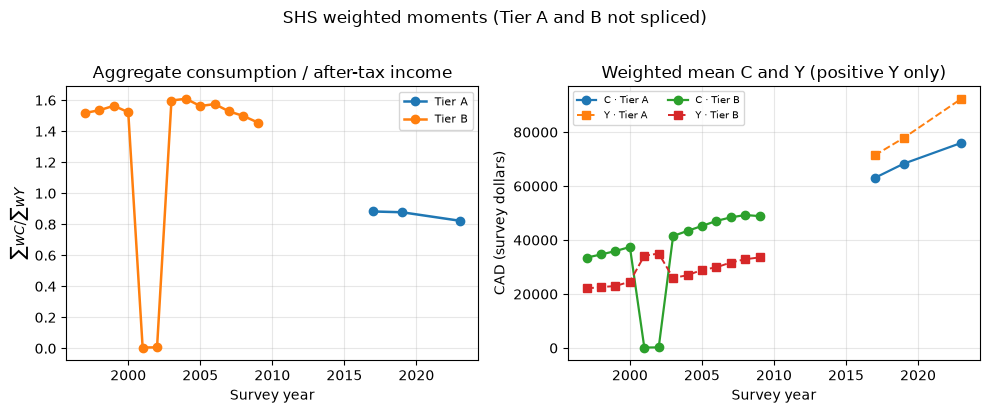

Wrote c:\Users\thoma\Dropbox\HAmodel\portfolio_olg\output\survey\shs_cy_moments.png


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sm = shs_m.copy()
# Prefer explicit tier column from groupby; fall back if duplicated/overwritten
if "tier" not in sm.columns:
    raise KeyError("shs_m missing tier — re-run with by=['tier', 'year']")

for tier, g in sm.groupby("tier", sort=True):
    g = g.sort_values("year")
    axes[0].plot(g["year"], g["cy_ratio"], marker="o", lw=1.8, label=f"Tier {tier}")
    axes[1].plot(g["year"], g["mean_consumption"], marker="o", lw=1.6, label=f"C · Tier {tier}")
    axes[1].plot(g["year"], g["mean_inc_net"], marker="s", ls="--", lw=1.4, label=f"Y · Tier {tier}")

axes[0].set_title("Aggregate consumption / after-tax income")
axes[0].set_xlabel("Survey year")
axes[0].set_ylabel(r"$\sum w C / \sum w Y$")
axes[0].legend(fontsize=8)
axes[0].grid(True, alpha=0.3)

axes[1].set_title("Weighted mean C and Y (positive Y only)")
axes[1].set_xlabel("Survey year")
axes[1].set_ylabel("CAD (survey dollars)")
axes[1].legend(fontsize=7, ncol=2)
axes[1].grid(True, alpha=0.3)

fig.suptitle("SHS weighted moments (Tier A and B not spliced)", y=1.02)
fig.tight_layout()
fig.savefig(out / "shs_cy_moments.png", dpi=140, bbox_inches="tight")
plt.show()
print("Wrote", out / "shs_cy_moments.png")
